# GPU • TorchScript

ResNet-18, 50 images du split de test CIFAR-10 et lots de 10. Trois exécutions dans des processus Python distincts.

**Runtime Colab** · GPU NVIDIA.
Exécuter d’abord le notebook 03 pour préparer les artefacts communs.

In [2]:
%pip -q install nvidia-ml-py reportlab "matplotlib>=3.8"

In [4]:
from google.colab import drive
from pathlib import Path
import os
import subprocess
import sys

drive.mount("/content/drive")
ROOT = Path("/content/drive/MyDrive/TP1_ResNet18")
ROOT.mkdir(parents=True, exist_ok=True)
CAMPAIGN = "colab-tp1"  # Même valeur dans les quatre notebooks.
ENV = dict(os.environ, OMP_NUM_THREADS="2", MKL_NUM_THREADS="2")
SCRIPT = Path("/content/tp1_benchmark.py")

def executer(*args):
    subprocess.run([sys.executable, str(SCRIPT), str(ROOT), *map(str, args)],
                   env=ENV, check=True)

Mounted at /content/drive


## Implémentation du pipeline

        Les trois processus rechargent le modèle et exécutent le même protocole. Les fichiers JSON
        contiennent les mesures, les prédictions et la configuration matérielle.

In [5]:
%%writefile /content/tp1_benchmark.py
import argparse
import hashlib
import json
import platform
import re
from pathlib import Path
from time import perf_counter

import numpy as np
import torch
import torchvision
from torchvision.models import resnet18

BATCH = 10
THREADS = 2
WARMUP = 5
PASSES = 10
RUNS = 3
DIGESTS = ("weights.pt", "test_data.pt", "model.onnx")
SCOPE = "Entrée CPU prétraitée → logits CPU, transferts inclus"


def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def write_json(path, data):
    tmp = path.with_suffix(".tmp")
    tmp.write_text(json.dumps(data, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    tmp.replace(path)


def torchscript_predictor(root, gpu):
    device = "cuda" if gpu else "cpu"
    model = resnet18(weights=None, num_classes=10).eval()
    model.load_state_dict(torch.load(root / "weights.pt", map_location="cpu", weights_only=True))
    with torch.no_grad():
        model = model.to(device)
        traced = torch.jit.freeze(torch.jit.trace(model, torch.zeros(BATCH, 3, 224, 224, device=device)))

    def predict(batch):
        return traced(batch.to(device)).cpu().numpy()
    return predict, str(torch.__version__)


def energy_reader(gpu):
    if gpu:
        try:
            import pynvml as nv
        except ImportError:
            return None, None
        try:
            nv.nvmlInit()
            props = torch.cuda.get_device_properties(0)
            uuid = getattr(props, "uuid", None)
            if nv.nvmlDeviceGetCount() == 1:
                handle = nv.nvmlDeviceGetHandleByIndex(0)
            elif uuid is not None:
                handle = nv.nvmlDeviceGetHandleByUUID(str(uuid))
            else:
                return None, None
            reader = lambda: nv.nvmlDeviceGetTotalEnergyConsumption(handle) / 1e3
            reader()
            return "GPU NVML", reader
        except (OSError, nv.NVMLError):
            return None, None
    zones = list(Path("/sys/class/powercap").glob("intel-rapl:[0-9]*"))
    try:
        packages = [p for p in zones if re.fullmatch(r"intel-rapl:\d+", p.name)
                    and (p / "name").read_text().strip().startswith("package")]
        if len(packages) == 1:
            package = packages[0]
            reader = lambda: int((package / "energy_uj").read_text()) / 1e6
            reader()
            return "Package CPU RAPL", reader
    except (OSError, ValueError):
        pass
    return None, None


def energy_value(reader):
    try:
        return reader() if reader else None
    except Exception:
        # Une erreur du compteur ne doit pas faire perdre les mesures de latence.
        return None


def cpu_name():
    if Path("/proc/cpuinfo").exists():
        match = re.search(r"^model name\s*:\s*(.+)$", Path("/proc/cpuinfo").read_text(), re.M)
        if match:
            return match.group(1)
    return platform.processor() or platform.machine()


def benchmark(root, pipeline, run, campaign, colab, launch_group):
    torch.set_num_threads(THREADS)
    torch.set_num_interop_threads(1)
    gpu = pipeline.startswith("gpu_")
    if gpu:
        if not torch.cuda.is_available():
            raise RuntimeError("Activer un GPU NVIDIA dans Colab.")
        torch.backends.cudnn.allow_tf32 = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.benchmark = False
    manifest = json.loads((root / "manifest.json").read_text())
    for name in DIGESTS:
        if sha256(root / name) != manifest["files"][name]:
            raise RuntimeError(f"Fichier commun modifié ou incomplet : {name}")
    data = torch.load(root / "test_data.pt", map_location="cpu", weights_only=True)
    if data["X"].shape != (50, 3, 224, 224) or data["Y"].shape != (50,):
        raise RuntimeError("Les données d’évaluation doivent contenir 50 images.")
    batches, labels = data["X"].split(BATCH), data["Y"].numpy()
    predict, version = torchscript_predictor(root, gpu)
    source, reader = energy_reader(gpu)
    with torch.inference_mode():
        for i in range(WARMUP):
            predict(batches[i % len(batches)])
        if gpu:
            torch.cuda.synchronize()
        durations = []
        started_energy = energy_value(reader)
        expected = None
        for _ in range(PASSES):
            outputs = []
            for batch in batches:
                start = perf_counter()
                logits = predict(batch)
                durations.append(perf_counter() - start)
                outputs.append(logits)
            logits = np.concatenate(outputs)
            if not np.isfinite(logits).all():
                raise RuntimeError("Logits non finis.")
            predictions = logits.argmax(axis=1)
            if expected is None:
                expected = predictions
            elif not np.array_equal(predictions, expected):
                raise RuntimeError("Prédictions variables pendant cette exécution.")
        ended_energy = energy_value(reader)
    energy = None
    if started_energy is not None and ended_energy is not None and ended_energy > started_energy:
        energy = ended_energy - started_energy
    count = len(labels) * PASSES
    result = {
        "pipeline": pipeline, "run": run, "campaign": campaign, "colab": colab,
        "launch_group": launch_group,
        "manifest": manifest["files"], "indices": data["indices"],
        "labels": labels.tolist(), "predictions": expected.tolist(),
        "metrics": {"debit_images_s": count / sum(durations),
                    "latence_ms_lot": 1000 * float(np.mean(durations)),
                    "top1_pct": 100 * float(np.mean(expected == labels)),
                    "energie_j": energy, "energie_j_image": energy / count if energy else None},
        "metadata": {"cpu": cpu_name(), "gpu": torch.cuda.get_device_name(0) if gpu else None,
                     "python": platform.python_version(), "torch": str(torch.__version__),
                     "torchvision": torchvision.__version__, "runtime": version,
                     "cuda": torch.version.cuda if gpu else None,
                     "cudnn": torch.backends.cudnn.version() if gpu else None,
                     "threads": THREADS, "batch": BATCH, "passes": PASSES, "warmup": WARMUP,
                     "precision": "FP32 (TF32 désactivé sur GPU)", "scope": SCOPE,
                     "energy_sensor": source}
    }
    write_json(root / "mesures" / campaign / f"{pipeline}_{run}.json", result)
    print(pipeline, run, result["metrics"], flush=True)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("root", type=Path)
    parser.add_argument("pipeline", choices=('gpu_torchscript',))
    parser.add_argument("--run", type=int, choices=range(1, RUNS + 1))
    parser.add_argument("--campaign", default="colab-tp1")
    parser.add_argument("--colab", action="store_true")
    parser.add_argument("--groupe", default=None)
    args = parser.parse_args()
    if args.run is None or not re.fullmatch(r"[A-Za-z0-9_-]+", args.campaign):
        parser.error("Indiquer un numéro d’exécution et un nom de campagne valide.")
    (args.root / "mesures" / args.campaign).mkdir(parents=True, exist_ok=True)
    benchmark(args.root, args.pipeline, args.run, args.campaign, args.colab, args.groupe)

Overwriting /content/tp1_benchmark.py


## Mesures et statistiques

In [6]:
import json
import uuid
import pandas as pd

if not (ROOT / "manifest.json").exists():
    raise FileNotFoundError("Exécuter d’abord la préparation avec le notebook 03.")
PIPELINE = 'gpu_torchscript'
inputs = ROOT / "mesures" / CAMPAIGN
groupe = uuid.uuid4().hex
for numero in range(1, 4):
    executer(PIPELINE, "--campaign", CAMPAIGN, "--run", numero, "--colab", "--groupe", groupe)
mesures = [json.loads((inputs / f"{PIPELINE}_{i}.json").read_text()) for i in range(1, 4)]
df = pd.DataFrame([r["metrics"] for r in mesures], dtype=float)
print("Environnement :", mesures[-1]["metadata"])
display(df.rename_axis("exécution").set_axis(range(1, 4)))
display(df.agg(["count", "mean", "std", "min", "max"]))

Environnement : {'cpu': 'Intel(R) Xeon(R) CPU @ 2.00GHz', 'gpu': 'Tesla T4', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'torchvision': '0.29.1+cu130', 'runtime': '2.14.1+cu130', 'cuda': '13.0', 'cudnn': 92800, 'threads': 2, 'batch': 10, 'passes': 10, 'warmup': 5, 'precision': 'FP32 (TF32 désactivé sur GPU)', 'scope': 'Entrée CPU prétraitée → logits CPU, transferts inclus', 'energy_sensor': 'GPU NVML'}


,debit_images_s,latence_ms_lot,top1_pct,energie_j,energie_j_image
1,824.357312,12.130662,76.0,36.352,0.072704
2,831.600468,12.025005,76.0,38.793,0.077586
3,793.915421,12.595800,76.0,43.227,0.086454


,debit_images_s,latence_ms_lot,top1_pct,energie_j,energie_j_image
count,3.000000,3.000000,3.0,3.000000,3.000000
mean,816.624400,12.250489,76.0,39.457333,0.078915
std,19.997228,0.303678,0.0,3.485314,0.006971
min,793.915421,12.025005,76.0,36.352000,0.072704
max,831.600468,12.595800,76.0,43.227000,0.086454


## Synthèse et rapport

Exécuter après les 12 mesures de la campagne. L’archive de résultats contient
le rapport PDF, le README mis à jour, les graphiques, les mesures et les tableaux CSV.

In [7]:
%%writefile /content/tp1_analyse.py
import argparse
import csv
import itertools
import json
import math
from collections import Counter
from pathlib import Path
from statistics import mean, stdev

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from reportlab.lib import colors
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import mm
from reportlab.platypus import (
    Image, PageBreak, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle,
)
from xml.sax.saxutils import escape

PIPELINES = {
    "cpu_openvino": "CPU OpenVINO",
    "cpu_torchscript": "CPU TorchScript",
    "gpu_tensorrt": "GPU TensorRT",
    "gpu_torchscript": "GPU TorchScript",
}
METRICS = {
    "debit_images_s": ("Débit", "images/s"),
    "latence_ms_lot": ("Latence moyenne par lot", "ms"),
    "top1_pct": ("Précision Top-1", "%"),
    "energie_j": ("Énergie pour 500 inférences", "J"),
    "energie_j_image": ("Énergie par image", "J/image"),
}
INK = "#172942"
TEAL = "#08675e"
BLUE = "#356cb0"


def load(folder):
    results = {key: [] for key in PIPELINES}
    for path in sorted(folder.glob("*.json")):
        row = json.loads(path.read_text())
        if row["pipeline"] not in results:
            raise ValueError(f"Pipeline inconnu dans {path.name}.")
        results[row["pipeline"]].append(row)
    all_rows = list(itertools.chain.from_iterable(results.values()))
    if not all_rows:
        return results
    reference = all_rows[0]
    if len(reference["indices"]) != 50 or len(set(reference["indices"])) != 50:
        raise ValueError("Le sous-ensemble doit contenir 50 indices uniques.")
    for key, rows in results.items():
        if len({r.get("launch_group") for r in rows}) > 1:
            raise ValueError(f"La série {key} mélange plusieurs lancements du notebook.")
        if len({r["run"] for r in rows}) != len(rows):
            raise ValueError(f"Exécutions dupliquées pour {key}.")
        for row in rows:
            for field in ("campaign", "manifest", "indices", "labels", "colab"):
                if row[field] != reference[field]:
                    raise ValueError(f"Campagne incompatible, champ {field}.")
            for field in ("threads", "batch", "passes", "warmup", "precision", "scope"):
                if row["metadata"][field] != reference["metadata"][field]:
                    raise ValueError(f"Protocole incompatible, champ {field}.")
            if len(row["labels"]) != 50 or len(row["predictions"]) != 50:
                raise ValueError("Il faut une prédiction et une étiquette par image.")
            if any(not 0 <= p < 10 for p in row["predictions"] + row["labels"]):
                raise ValueError("Classe prédite ou réelle hors de CIFAR-10.")
            if not math.isclose(row["metrics"]["top1_pct"], 2 * sum(
                p == y for p, y in zip(row["predictions"], row["labels"])
            )):
                raise ValueError("Précision incohérente avec les prédictions sauvegardées.")
    return results


def summarize(results, folder):
    stats = {}
    for key, rows in results.items():
        for metric in METRICS:
            values = [row["metrics"][metric] for row in rows if row["metrics"][metric] is not None]
            if values:
                stats[key, metric] = (len(values), mean(values),
                                      stdev(values) if len(values) > 1 else None,
                                      min(values), max(values))
    with (folder / "statistiques.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(("pipeline", "indicateur", "n", "moyenne", "ecart_type", "minimum", "maximum"))
        for (key, metric), values in stats.items():
            writer.writerow((key, metric, *values))
    return stats


def agreements(results, folder):
    comparisons = {}
    with (folder / "accord_predictions.csv").open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(("pipeline_a", "execution_a", "pipeline_b", "execution_b",
                         "predictions_identiques_sur_50"))
        for (ka, kb) in itertools.combinations_with_replacement(PIPELINES, 2):
            a, b = results[ka], results[kb]
            pairs = itertools.combinations(a, 2) if ka == kb else itertools.product(a, b)
            counts = []
            for ra, rb in pairs:
                count = sum(x == y for x, y in zip(ra["predictions"], rb["predictions"]))
                writer.writerow((ka, ra["run"], kb, rb["run"], count))
                counts.append(count)
            if counts:
                comparisons[ka, kb] = (min(counts), max(counts))
    return comparisons


def plots(stats, folder, results):
    charts = {}
    pilot = any(not row["colab"] for rows in results.values() for row in rows)
    for metric, (title, unit) in METRICS.items():
        observed = [(k, stats[k, metric]) for k in PIPELINES if (k, metric) in stats]
        if not observed:
            continue
        fig, ax = plt.subplots(figsize=(7.2, 2.9), layout="constrained")
        for i, key in enumerate(PIPELINES):
            item = stats.get((key, metric))
            if item is None:
                ax.text(i, 0.025, "N/D", ha="center", transform=ax.get_xaxis_transform())
                continue
            n, avg, sd, low, high = item
            ax.bar(i, avg, yerr=sd, capsize=5, width=0.62,
                   color=TEAL if key.startswith("cpu") else BLUE, zorder=2)
            if metric.startswith("energie"):
                source = next(row["metadata"]["energy_sensor"] for row in results[key]
                              if row["metrics"][metric] is not None)
                ax.text(i, 0.015, "RAPL" if source and "RAPL" in source else "NVML",
                        ha="center", color="white", transform=ax.get_xaxis_transform(), fontsize=8)
        ax.set(xlim=(-0.6, 3.6), ylabel=unit, title=f"{title} — pilote CPU local" if pilot else title,
               xticks=range(4), xticklabels=list(PIPELINES.values()))
        if metric == "top1_pct":
            ax.set_ylim(0, 105)
        ax.grid(axis="y", alpha=.2, zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
        chart = folder / f"{metric}.png"
        fig.savefig(chart, dpi=180)
        plt.close(fig)
        charts[metric] = chart
    return charts


def fr(x):
    return "N/D" if x is None else f"{x:.3f}".replace(".", ",")


def summarize_pair(stats, results, a, b):
    if any((key, "debit_images_s") not in stats for key in (a, b)):
        return "La comparaison de cette paire attend les deux séries de mesures."
    da, db = [stats[k, "debit_images_s"][1] for k in (a, b)]
    same_hardware = all(
        len({r["metadata"][field] for key in (a, b) for r in results[key]}) == 1
        for field in ("cpu", "gpu")
    )
    names = [PIPELINES[a], PIPELINES[b]]
    faster, slower = (names[0], names[1]) if da >= db else (names[1], names[0])
    detail = ("Les modèles matériels déclarés concordent au sein de cette paire."
              if same_hardware else "Les modèles matériels diffèrent. Le classement combine les effets du runtime et du matériel.")
    if math.isclose(da, db):
        return f"Le débit moyen est équivalent pour les deux chaînes. {detail}"
    return f"{faster} atteint {fr(max(da, db) / min(da, db))}× le débit moyen de {slower}. {detail}"


def report(path, results, stats, comparisons, charts):
    styles = getSampleStyleSheet()
    styles["Title"].textColor = colors.HexColor(INK)
    styles["Title"].fontSize, styles["Title"].leading = 27, 31
    styles["Title"].alignment = 0
    styles["Heading1"].textColor = colors.HexColor(TEAL)
    styles["Heading1"].spaceBefore = 15
    styles["Heading2"].textColor = colors.HexColor(INK)
    styles["BodyText"].fontSize, styles["BodyText"].leading = 10.3, 15
    styles["BodyText"].spaceAfter = 7
    styles.add(ParagraphStyle("SmallTP", parent=styles["BodyText"], fontSize=8.1, leading=11, spaceAfter=2))
    story = []

    def p(value, style="BodyText"):
        story.append(Paragraph(value, styles[style]))

    def table(rows, widths):
        rows = [[Paragraph(escape(str(cell)), styles["SmallTP"]) for cell in row] for row in rows]
        block = Table(rows, colWidths=[w * mm for w in widths], repeatRows=1, hAlign="LEFT")
        block.setStyle(TableStyle([
            ("VALIGN", (0, 0), (-1, -1), "TOP"),
            ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#dceeea")),
            ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f1f5fa")]),
            ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
        ]))
        story.extend((block, Spacer(1, 8)))

    complete = all(len(r) == 3 for r in results.values())
    p("TP1  /  DÉPLOIEMENT DE MODÈLES", "SmallTP")
    p("Quatre chaînes d’inférence pour ResNet-18", "Title")
    p("Taha El Afdel • EIGSI Casablanca")
    local = any(not r["colab"] for rows in results.values() for r in rows)
    if local:
        p(f"Rapport provisoire • pilote CPU local ({sum(map(len, results.values()))} exécutions) • campagne Colab en attente")
    elif complete:
        p("Campagne expérimentale Google Colab" if all(r[0]["colab"] for r in results.values())
          else "Mesures hors Google Colab")
    else:
        p(f"Rapport provisoire • {sum(map(len, results.values()))}/12 exécutions disponibles")
    p("1. Architecture des pipelines", "Heading1")
    table([
        ("PyTorch", "Format", "Optimisation et exécution", "Matériel"),
        ("ResNet-18", "ONNX, opset 17", "OpenVINO Runtime, kernels CPU dont oneDNN selon les opérateurs", "CPU"),
        ("ResNet-18", "TorchScript", "Traçage et gel du graphe, opérateurs PyTorch et kernels CPU", "CPU"),
        ("ResNet-18", "ONNX, opset 17", "TensorRT, sélection de tactiques et kernels CUDA", "GPU NVIDIA"),
        ("ResNet-18", "TorchScript", "Traçage et gel du graphe, kernels CUDA et cuDNN selon les opérateurs", "GPU NVIDIA"),
    ], [28, 30, 87, 25])
    p("L’export ONNX fournit un graphe aux runtimes OpenVINO et TensorRT. TorchScript conserve le graphe dans l’écosystème PyTorch. La configuration de TensorRT permet au moteur de sélectionner ses tactiques pendant la construction. Les quatre chaînes utilisent le même modèle en FP32. Sur GPU, TF32 est désactivé.")
    p("2. Modèle et données", "Heading1")
    p("ResNet-18 part des poids IMAGENET1K_V1. Le classifieur ImageNet à 1 000 sorties est remplacé par une tête linéaire à 10 sorties. Elle est entraînée pendant deux époques avec Adam (0,001) sur 5 000 images du split d’entraînement CIFAR-10. Le backbone est gelé et reste en mode évaluation. Les quatre chaînes reçoivent ensuite les mêmes poids et les mêmes entrées, vérifiés par empreinte SHA-256.")
    p("Les 50 images uniques sont tirées du split de test avec la graine 42, puis redimensionnées à 256 × 256 et recadrées au centre à 224 × 224. Les canaux RGB sont ramenés dans [0,1], puis normalisés avec les moyennes (0,485 ; 0,456 ; 0,406) et les écarts-types (0,229 ; 0,224 ; 0,225).")
    if any(results.values()):
        ref = next(iter(next(rows for rows in results.values() if rows)))
        counts = Counter(ref["labels"])
        p("Effectifs de test pour les classes CIFAR-10 dans l’ordre des identifiants : "
          + ", ".join(str(counts[i]) for i in range(10)) + ".")
    story.append(PageBreak())

    p("3. Protocole expérimental", "Heading1")
    p("Chaque chaîne est lancée trois fois dans trois processus Python distincts. Chaque processus recharge le modèle, construit son exécuteur et effectue cinq lots d’échauffement. Il traite ensuite dix passages sur les 50 images, par lots de 10. Le calcul CPU est limité à deux threads d’inférence et la boucle soumet un seul lot à la fois.")
    p("Le chronomètre couvre chaque appel, depuis le lot prétraité en RAM jusqu’aux logits disponibles en RAM. Pour le GPU, les copies aller-retour sont incluses et la copie des logits attend la fin du calcul. La préparation des données, la construction du moteur, l’échauffement et le calcul de la précision sont hors chronométrage de l’inférence.")
    p("Débit = 500 / somme des durées en secondes. Latence = durée moyenne d’un lot en millisecondes. Top-1 = proportion des 50 étiquettes correctement prédites, avec un pas de 2 points. Les passages supplémentaires stabilisent le chronométrage sans augmenter la taille de l’échantillon de qualité.")
    p("Les barres d’erreur représentent l’écart-type d’échantillon entre processus. L’énergie est la différence d’un compteur sur les dix passages, divisée par 500 pour l’énergie par image. Cette fenêtre inclut l’agrégation des prédictions entre passages. NVML rapporte l’énergie du GPU et RAPL celle du package CPU. Ces périmètres distincts ne permettent pas un bilan énergétique global CPU/GPU.")
    p("4. Environnements et disponibilité", "Heading1")
    hardware = [("Pipeline", "n/3", "CPU / GPU et runtime")]
    for key, label in PIPELINES.items():
        rows = results[key]
        configs = sorted({f'{r["metadata"]["cpu"]} / {r["metadata"]["gpu"] or "CPU"} • {r["metadata"]["runtime"]}' for r in rows})
        hardware.append((label, f"{len(rows)}/3", " | ".join(configs) or "Mesures en attente"))
    table(hardware, [43, 15, 112])
    if local:
        p("Le pilote CPU a utilisé CIFAR-10 dans sa distribution Parquet UofT sur Hugging Face. La tête a été entraînée sur CPU pour cette vérification locale. Les chiffres décrivent cet hôte. La campagne Colab doit exécuter les quatre chaînes avec ses propres artefacts communs.")
    p("Les fichiers JSON versionnent les mesures individuelles, les prédictions, les indices, les versions logicielles et les métadonnées de chaque lancement. L’environnement Colab peut changer entre notebooks. Une comparaison intra-architecture est plus interprétable lorsque les modèles de CPU et GPU concordent.")
    p("Références techniques", "Heading2")
    for label, url in (
        ("Torchvision · poids et prétraitement ResNet-18", "https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html"),
        ("OpenVINO · ordonnancement et paramètres CPU", "https://docs.openvino.ai/2024/openvino-workflow/running-inference/inference-devices-and-modes/cpu-device/performance-hint-and-thread-scheduling.html"),
        ("NVIDIA · API Python TensorRT", "https://docs.nvidia.com/deeplearning/tensorrt/10.x.x/inference-library/python-api-docs.html"),
        ("NVIDIA · compteur énergétique NVML", "https://docs.nvidia.com/deploy/archive/R535/nvml-api/group__nvmlDeviceQueries.html"),
    ):
        p(f'<link href="{url}" color="{TEAL}">{label}</link>', "SmallTP")

    story.append(PageBreak())
    p("5. Résultats et variabilité", "Heading1")
    if not stats:
        p("Les quatre séries Colab attendent leur exécution. Les tableaux chiffrés, les barres d’erreur et les conclusions expérimentales seront générés à partir des mesures enregistrées.")
        p("Le débit et la latence seront interprétés par paire CPU ou GPU. La comparaison des prédictions portera sur chaque image, entre pipelines et entre répétitions. L’énergie sera présentée lorsque les compteurs de la machine donnent une mesure exploitable.")
    else:
        values = [("Pipeline", "Indicateur", "n", "Moyenne", "Écart-type", "Min.", "Max.")]
        compact = ["images/s", "ms/lot", "Top-1 (%)", "J/500 images", "J/image"]
        for key, label in PIPELINES.items():
            for metric, unit in zip(METRICS, compact):
                row = stats.get((key, metric))
                values.append((label, unit, row[0] if row else 0,
                               *([fr(x) for x in row[1:]] if row else ["N/D"] * 4)))
        table(values, [37, 31, 9, 24, 24, 22, 23])
        for a, b in (("cpu_openvino", "cpu_torchscript"), ("gpu_tensorrt", "gpu_torchscript")):
            p(summarize_pair(stats, results, a, b))
        variation = [(100 * s[2] / s[1], PIPELINES[k]) for (k, m), s in stats.items()
                     if m == "debit_images_s" and s[2] is not None and s[1] > 0]
        if variation:
            high, label = max(variation)
            p(f"La dispersion relative du débit atteint au maximum {fr(high)} % ({label}). Trois mesures donnent un premier ordre de grandeur de la stabilité sous la charge observée.")
        story.append(PageBreak())
        p("6. Performances mesurées", "Heading1")
        for metric in ("debit_images_s", "latence_ms_lot"):
            if metric in charts:
                story.append(Image(str(charts[metric]), width=164 * mm, height=66 * mm))
        p("À taille de lot fixe et en mode séquentiel, un débit plus élevé correspond à une latence par lot plus faible. Les temps GPU incluent la communication entre l’hôte et le périphérique. Les mesures agrègent le matériel, les transferts et l’exécution du graphe.")
        story.append(PageBreak())
        p("7. Qualité des prédictions", "Heading1")
        if "top1_pct" in charts:
            story.append(Image(str(charts["top1_pct"]), width=164 * mm, height=66 * mm))
        agreement_rows = [("Pipeline A", "Pipeline B", "Accord min.–max. / 50")]
        agreement_rows += [(PIPELINES[a], PIPELINES[b], str(minimum) if minimum == maximum else f"{minimum}–{maximum}")
                           for (a, b), (minimum, maximum) in comparisons.items()]
        table(agreement_rows, [55, 55, 60])
        cross = [mn for (a, b), (mn, mx) in comparisons.items() if a != b]
        if cross:
            p("Les prédictions coïncident sur les 50 images dans toutes les comparaisons entre pipelines observées."
              if min(cross) == 50 else f"Au moins une comparaison entre pipelines diverge sur {50 - min(cross)} images. Les accords par image permettent de repérer des changements que la seule précision moyenne peut masquer.")
        tops = [s[1] for (k, m), s in stats.items() if m == "top1_pct"]
        if min(tops) == max(tops):
            p(f"Toutes les chaînes mesurées atteignent {fr(tops[0])} % de précision moyenne.")
        else:
            p(f"La précision moyenne des chaînes mesurées varie de {fr(min(tops))} % à {fr(max(tops))} %.")
        p("Les 50 images évaluent l’accord sur le sous-ensemble étudié. La taille de cet échantillon limite la portée des conclusions sur la généralisation.")
        if "energie_j" in charts:
            story.append(PageBreak())
        p("8. Énergie et portée des mesures", "Heading1")
        if "energie_j" in charts:
            for metric in ("energie_j", "energie_j_image"):
                if metric in charts:
                    story.append(Image(str(charts[metric]), width=164 * mm, height=66 * mm))
            for keys in (("cpu_openvino", "cpu_torchscript"), ("gpu_tensorrt", "gpu_torchscript")):
                measured = [key for key in keys if (key, "energie_j_image") in stats]
                if len(measured) == 2:
                    a, b = sorted(measured, key=lambda key: stats[key, "energie_j_image"][1])
                    ea, eb = [stats[key, "energie_j_image"][1] for key in (a, b)]
                    p(f"Dans cette paire, {PIPELINES[a]} affiche {fr(ea)} J/image et {PIPELINES[b]} {fr(eb)} J/image. Le compteur mesure tout le périphérique pendant la fenêtre de mesure.")
        else:
            p("Aucun compteur énergétique exploitable sur les exécutions disponibles.")

    def footer(canvas, doc):
        canvas.setStrokeColor(colors.HexColor("#d5dfe8"))
        canvas.line(20 * mm, 17 * mm, 190 * mm, 17 * mm)
        canvas.setFont("Helvetica", 8)
        canvas.setFillColor(colors.HexColor(INK))
        canvas.drawString(20 * mm, 12 * mm, "TP1 / Déploiement ResNet-18")
        canvas.drawRightString(190 * mm, 12 * mm, str(doc.page))

    doc = SimpleDocTemplate(str(path), title="TP1 - Déploiement de ResNet-18", author="Taha El Afdel",
                            pagesize=(210 * mm, 297 * mm), leftMargin=20 * mm, rightMargin=20 * mm,
                            topMargin=19 * mm, bottomMargin=22 * mm)
    doc.build(story, onFirstPage=footer, onLaterPages=footer)


def run(inputs, outputs, allow_partial=False):
    results = load(inputs)
    if not allow_partial and not all(len(rows) == 3 and all(r["colab"] for r in rows)
                                     for rows in results.values()):
        raise RuntimeError("La synthèse finale attend 3 mesures Colab pour chacun des 4 pipelines.")
    outputs.mkdir(parents=True, exist_ok=True)
    stats = summarize(results, outputs)
    comparisons = agreements(results, outputs)
    charts = plots(stats, outputs, results)
    path = outputs / "Rapport_TP1.pdf"
    report(path, results, stats, comparisons, charts)
    return path


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("inputs", type=Path)
    parser.add_argument("outputs", type=Path)
    parser.add_argument("--provisoire", action="store_true")
    args = parser.parse_args()
    print(run(args.inputs, args.outputs, args.provisoire))

Writing /content/tp1_analyse.py


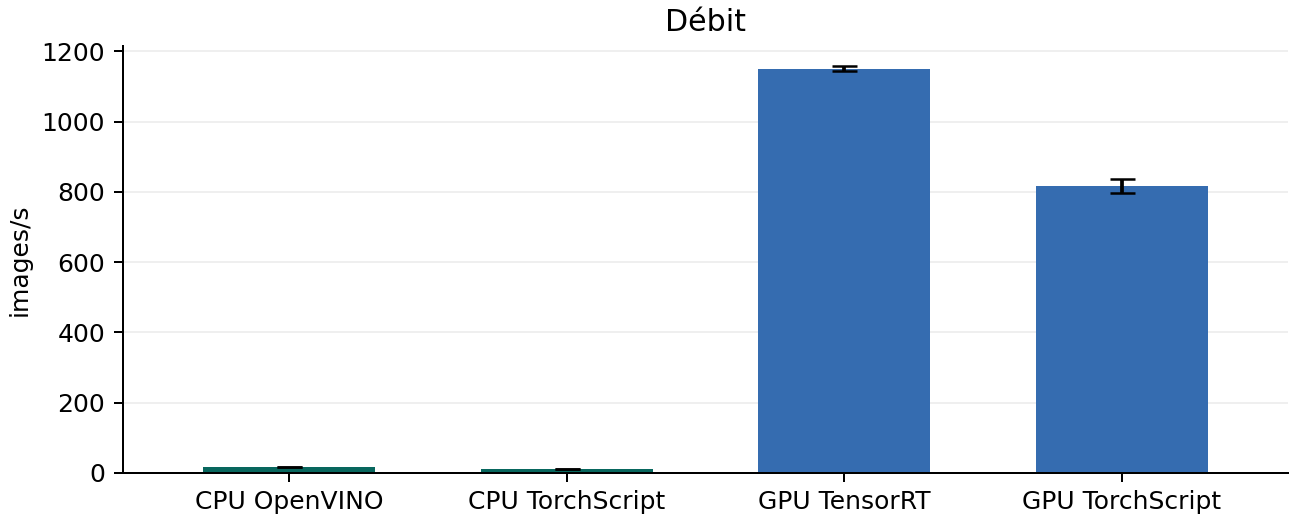

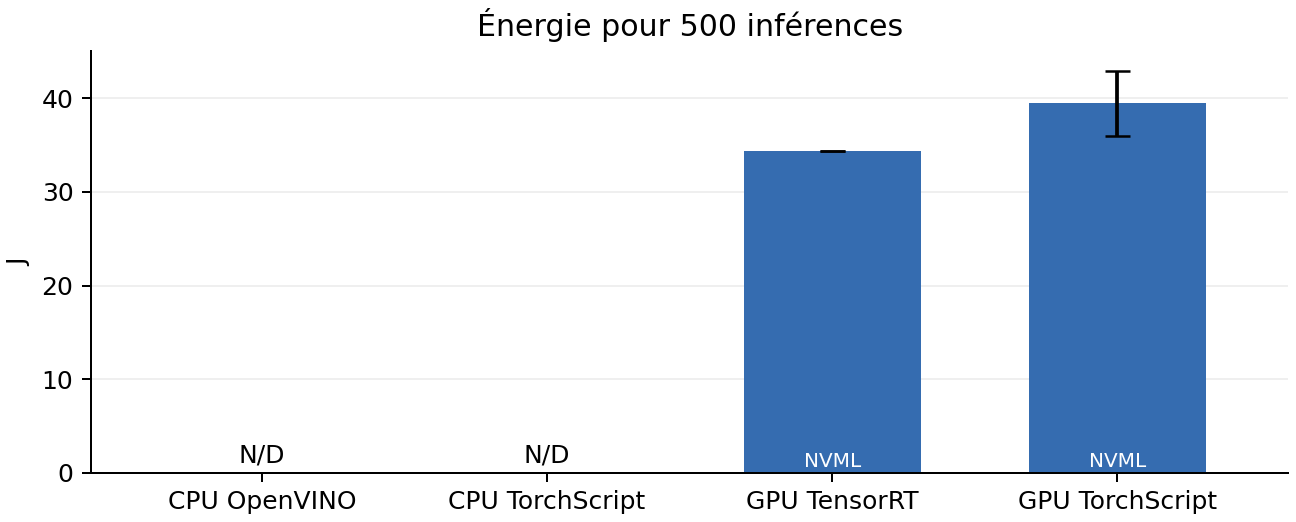

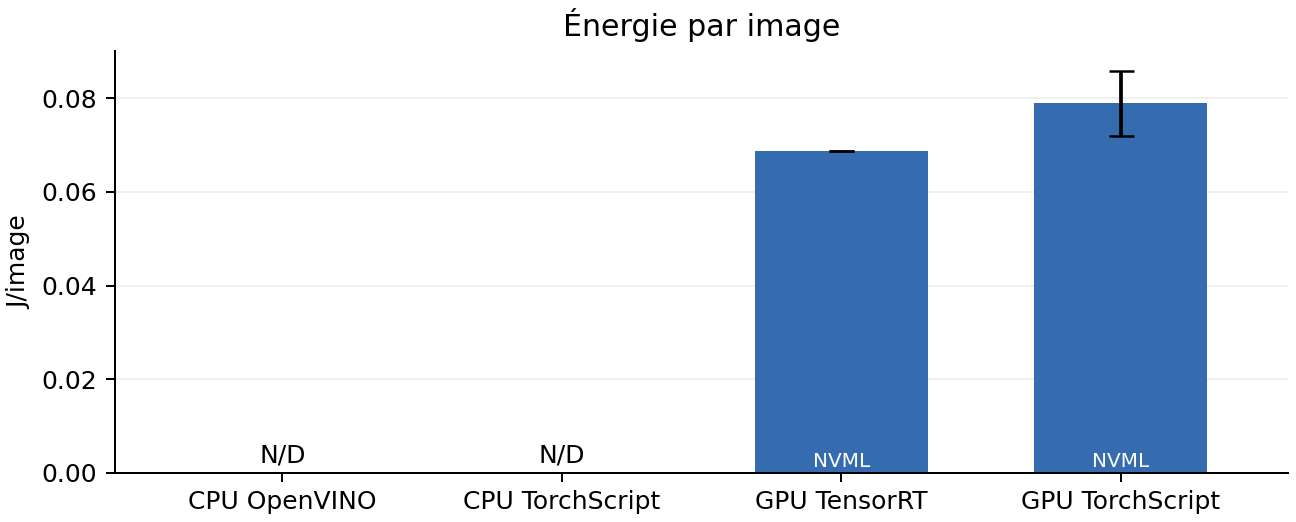

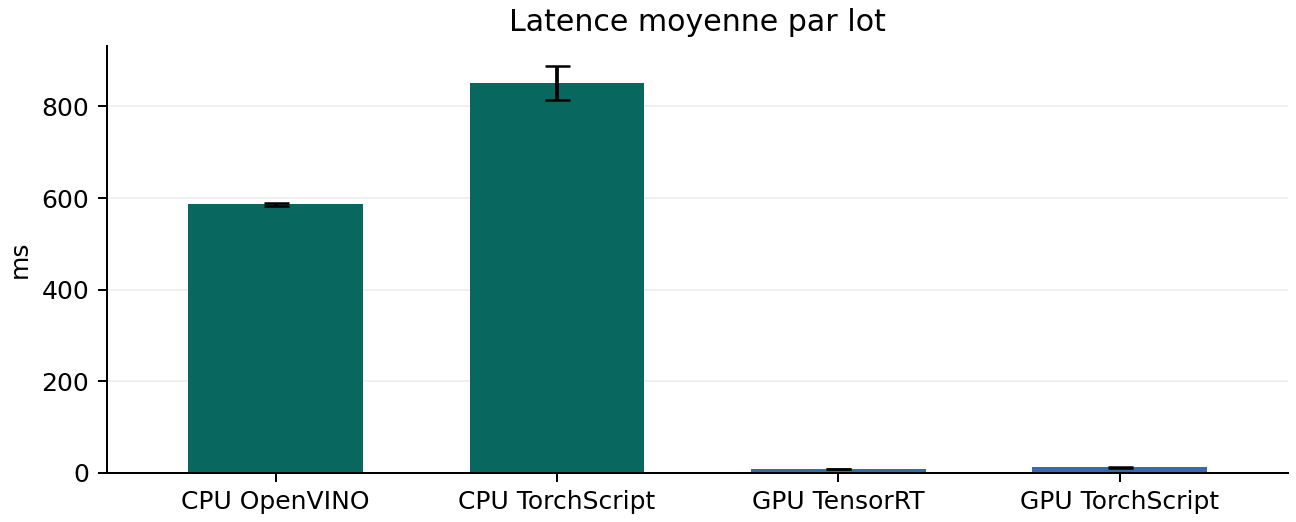

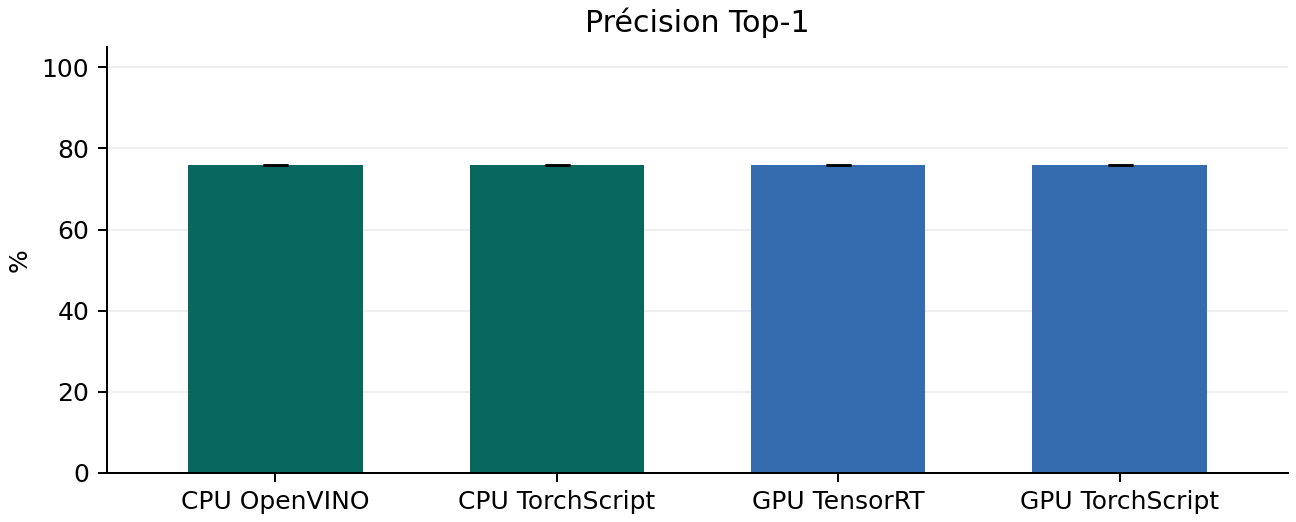

Archive prête dans Google Drive : /content/drive/MyDrive/TP1_ResNet18/TP1_Resultats_colab-tp1.zip


In [8]:
README_BASE = '# TP1 — Déploiement de ResNet-18 sur CPU et GPU\n\nLe projet compare quatre chaînes d’inférence Google Colab sur les mêmes 50 images de test CIFAR-10, avec un lot de 10 et des calculs FP32. Le backbone provient des poids ImageNet de ResNet-18. Une tête linéaire entraînée sur le split d’entraînement de CIFAR-10 produit les dix classes du TP.\n\n## Notebooks\n\n| Fichier | Chaîne | Runtime Colab |\n| --- | --- | --- |\n| [03_GPU_TensorRT.ipynb](notebooks/03_GPU_TensorRT.ipynb) | Préparation commune puis PyTorch → ONNX → TensorRT → CUDA | GPU NVIDIA |\n| [04_GPU_TorchScript.ipynb](notebooks/04_GPU_TorchScript.ipynb) | PyTorch → TorchScript → CUDA, puis synthèse | GPU NVIDIA |\n| [01_CPU_OpenVINO.ipynb](notebooks/01_CPU_OpenVINO.ipynb) | PyTorch → ONNX → OpenVINO → CPU | CPU |\n| [02_CPU_TorchScript.ipynb](notebooks/02_CPU_TorchScript.ipynb) | PyTorch → TorchScript → CPU | CPU |\n\n## Exécution sur Colab\n\n1. Importer les quatre fichiers `.ipynb` via **Fichier → Importer un notebook**. Utiliser le même compte Google pour le dossier Drive `MyDrive/TP1_ResNet18`. Sur Colab, choisir l’accélérateur dans **Exécution → Modifier le type d’exécution**.\n2. Exécuter **03** sur GPU en premier. Il prépare et sauvegarde les poids, l’export ONNX et les 50 images normalisées, puis mesure TensorRT. La préparation est réutilisée tant que son manifeste est présent.\n3. Exécuter **01** et **02** en mode CPU, puis **04** sur GPU. Relever les modèles matériels affichés. Utiliser le même type de GPU pour **03** et **04** si Colab le permet. Garder le même nom de campagne dans les quatre notebooks et choisir un nouveau nom pour une campagne distincte.\n4. Dans **04**, exécuter la section **Synthèse et rapport**. Elle valide les 12 fichiers JSON, affiche les graphiques et génère `TP1_Resultats_colab-tp1.zip` avec le nom de campagne par défaut sur Drive. Extraire cette archive à la racine du dépôt pour mettre à jour le PDF, le résumé ci-dessous et les résultats.\n5. Publier le dépôt en visibilité **Public**, vérifier l’accès en navigation privée, puis déposer son URL sur Moodle.\n\n## Fichiers livrés\n\n- `notebooks/` contient les quatre implémentations et le code de synthèse.\n- [Rapport_TP1.pdf](Rapport_TP1.pdf) présente l’architecture, le protocole et le bilan expérimental dès que les mesures sont disponibles.\n- `resultats/` reçoit les JSON bruts, `statistiques.csv` (moyenne, écart-type d’échantillon, minimum, maximum), `accord_predictions.csv` et les graphiques.\n\nChaque pipeline effectue trois lancements dans des processus distincts. Après échauffement, chaque lancement mesure dix passages sur le même sous-ensemble. La latence couvre les lots prétraités en RAM jusqu’aux logits en RAM, y compris les transferts GPU. Les valeurs énergétiques dépendent de la disponibilité des compteurs NVML ou RAPL et sont exprimées en joules et joules par image.\n\nLes mesures locales de vérification, lorsqu’elles sont présentes, se trouvent dans `resultats/pilote_cpu/`. La campagne Colab fournit les résultats attendus pour le rendu.\n\n'
import shutil
from tempfile import TemporaryDirectory
from IPython.display import Image, display
from tp1_analyse import agreements, load, run, summarize, summarize_pair

tmp = TemporaryDirectory()
output = Path(tmp.name)
final_pdf = run(inputs, output / "resultats")
final_pdf.replace(output / "Rapport_TP1.pdf")
shutil.copytree(inputs, output / "resultats" / "bruts", dirs_exist_ok=True)

mesures = load(inputs)
bilan = summarize(mesures, output / "resultats")
accord = agreements(mesures, output / "resultats")
conclusions = []
for a, b in (("cpu_openvino", "cpu_torchscript"), ("gpu_tensorrt", "gpu_torchscript")):
    conclusions.append(summarize_pair(bilan, mesures, a, b))
minimum = min(ag[0] for (a, b), ag in accord.items() if a != b)
conclusions.append(f"L’accord entre pipelines est d’au moins {minimum}/50 prédictions.")
precision = [r[1] for (key, metric), r in bilan.items() if metric == "top1_pct"]
conclusions.append(f"La précision Top-1 moyenne s’étend de {min(precision):.1f} % à {max(precision):.1f} %.")
variabilite = [100 * r[2] / r[1] for (key, metric), r in bilan.items()
               if metric == "debit_images_s"]
conclusions.append(f"L’écart-type relatif maximal du débit est de {max(variabilite):.1f} %.")
readme = README_BASE + "## Principales conclusions\n\n"
readme += "\n".join(f"- {conclusion}" for conclusion in conclusions) + "\n"
(output / "README.md").write_text(readme, encoding="utf-8")
for chart in sorted((output / "resultats").glob("*.png")):
    display(Image(filename=str(chart)))
archive = shutil.make_archive(str(ROOT / f"TP1_Resultats_{CAMPAIGN}"), "zip", output)
tmp.cleanup()
print("Archive prête dans Google Drive :", archive)